# Global Sensitivity Analysis to Study the Impacts of Bed-Nets, Drug Treatment, and Their Efficacies on a Two-Strain Malaria Model

__Saminu Bala__, Department of Mathematical Sciences, Bayero University, Kano, Nigeria

__Bello Gimba__, Department of General Studies, School of Health Technology, Jahun, Nigeria

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the effective reproduction number $R_{\mathrm{eff}}$ of the two-strain (drug-sensitive and drug-resistant) malaria model of Bala and Gimba [[1]][R1], a closed-form function of 20 epidemiological and intervention parameters. It runs in Python 3 with numpy and `active_subspaces` v1.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import malaria_model as mm

SEED = 2019                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
TEX = {'psi_h': r'$\psi_h$', 'psi_v': r'$\psi_v$', 'T_s': r'$T_s$', 'b1': r'$b_1$', 'b2': r'$b_2$',
       'rho': r'$\rho$', 'b': r'$b$', 'beta_max': r'$\beta_{\max}$', 'beta_min': r'$\beta_{\min}$',
       'e': r'$e$', 'gamma': r'$\gamma$', 'r_r': r'$r_r$', 'r_s': r'$r_s$', 'beta': r'$\beta$',
       'delta_h': r'$\delta_h$', 'mu_h2': r'$\mu_{h2}$', 'mu_h': r'$\mu_h$', 'mu_v': r'$\mu_v$',
       'mu_v2': r'$\mu_{v2}$', 'mu_v3': r'$\mu_{v3}$'}
labels = [TEX[n] for n in mm.NAMES]
qlabel = r'$R_{\mathrm{eff}}$'

### Summary

Bala and Gimba [[1]][R1] build an eight-compartment human–mosquito malaria model with drug-sensitive and drug-resistant strains, insecticide-treated bed nets (ITNs) and treatment, derive its effective reproduction number in closed form, and rank the parameters by partial rank correlation coefficients (PRCC) on a Latin hypercube sample. We code $R_{\mathrm{eff}}$ (Eq. 19) with its exact gradient, show that the 20 parameters of the paper's PRCC figure are exactly those that enter $R_{\mathrm{eff}}$ (Table 3 lists 23), and reproduce the paper's five leading PRCC parameters in the paper's order and its fraction of samples with $R_{\mathrm{eff}} < 1$. The gradient-based active subspace of $R_{\mathrm{eff}}$ on 1000 Latin hypercube samples is one-dimensional with $\lambda_1/\lambda_2 = 10.6$, led by ITN efficacy, human recruitment and the minimum biting rate; this direction is stable, but the ratio rests on few samples (the 10 samples with the largest gradients hold 47 % of the trace of $\hat{\mathbf C}$, and without them $\lambda_1/\lambda_2 = 16.1$), and because $R_{\mathrm{eff}}$ is heavy-tailed a one-variable surrogate reaches only a leave-one-out $R^2$ of about 0.82.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See Constantine's book [[2]][R2] for the theory.

### The model

**Biting rate** (Eq. 1, p. 4). With ITN usage $b$ and ITN efficacy $\gamma$ ($0 \le b, \gamma \le 1$),
$$
a = \frac{\beta_{\max}\beta_{\min}}{(\beta_{\max}-\beta_{\min})\,b\gamma + \beta_{\min}},
$$
which falls from $\beta_{\max}$ (no nets) to $\beta_{\min}$ (everyone under a fully efficient net).

**Reproduction number.** The paper scales the eight-compartment model (Eq. 3, p. 6) by the total populations into six equations (Eq. 15, p. 10), with $\xi_1 = a b_1 N_v/N_h = a b_1 k_v\rho_1/k_h$, $\rho_1 = N_v^*/N_h^*$, and $k_1 = a b_2$ (p. 10), where the carrying capacities are (proof of Lemma 1, p. 8)
$$
k_v = \frac{\psi_v - \mu_v - \mu_{v3}\,b\gamma}{\mu_{v2}},\qquad k_h = \frac{\psi_h - \mu_h}{\mu_{h2}},
$$
and $p_1 = r_s + \delta_h + T_s + \psi_h$, $p_2 = r_r + \delta_h + \psi_h$, $p_3 = T_s(1-e)$ (p. 10). We follow this printed definition of $\xi_1$, with $\rho_1$ set to Table 3's $\rho$ (\"mosquitoes per human\", 2–8). This counts the mosquito-to-human ratio twice: $N_v/N_h = (k_v/k_h)\,\rho_1$, and $\rho_1$ is a ratio of the scaled populations $N_v^*/N_h^*$ (1 at the scaled equilibrium), so the ratio actually used is $\rho_1 k_v/k_h$ (printed below at the baselines). Whether $\rho_1$ was meant to be that scaled ratio or Table 3's 7 is an open question for the authors; the PRCC comparison below supports the printed formula with $k_v/k_h$ included. The next-generation matrices $F$ and $V$ (Eqs. 16–17, pp. 10–11; the method of [[6]][R6]) give (Eq. 19, p. 11)
$$
R_{\mathrm{eff}} = \frac{\xi_1 k_1 (1-\beta)}{p_2\psi_v} + \frac{k_1\xi_1\beta(p_2+p_3)}{p_2 p_1\psi_v} = R_r + R_s ,
$$
the resistant- and sensitive-strain parts of Eq. (20). Two remarks on the printed equations. (i) $R_{\mathrm{eff}}$ of Eq. (19) is the *square* of the spectral radius $\rho(FV^{-1})$, not the radius itself: each infection passes through a human and a mosquito generation. The threshold $R_{\mathrm{eff}} = 1$ is the same either way. (ii) The radicand of the printed Eq. (18), $-p_2p_1\psi_v\xi_1k_1(\beta p_1 + \beta - p_3 - \beta p_2 - p_1)$, does not agree with Eq. (19) (it is not even dimensionally consistent); the computed spectral radius has $\beta p_1 - \beta p_3 - \beta p_2 - p_1$ in its place, and then its square is Eq. (19). We check both numerically below.

**The quantity of interest** is $R_{\mathrm{eff}}$ (dimensionless). Writing $R_{\mathrm{eff}} = a^2 b_1 b_2\rho_1 (k_v/k_h)\,H/\psi_v$ with $H = (1-\beta)/p_2 + \beta(p_2+p_3)/(p_1p_2)$, the gradient is $\nabla R_{\mathrm{eff}} = R_{\mathrm{eff}}\,\nabla\ln R_{\mathrm{eff}}$, written out term by term in `malaria_model.reff`.

**Which inputs.** Table 3 (p. 19) lists 23 parameters with baseline values, ranges and distributions, while the text (p. 18–19) says that $R_{\mathrm{eff}}$ "was regulated by 20 various malaria-related epidemiological parameters" and that the Latin hypercube sample was "a 1000 by 20 matrix". The 20 are the parameters that enter $R_{\mathrm{eff}}$: three of the 23 rows, the immunity-loss rates $\alpha_s$ and $\alpha_r$ and the resistant fraction of infected mosquitoes $\alpha$, do not. $\alpha_s$, $\alpha_r$ enter only $c_1$, $c_2$, the removal rates of the recovered classes, which are not infected compartments; $\alpha$ splits new mosquito infections between two classes with the same removal rate $\psi_v$, so it cancels from the spectral radius. The paper's PRCC tornado plot for $R_{\mathrm{eff}}$ (Fig. 5, p. 21) has exactly the other 20. Five of them, $\mu_h, \mu_{h2}, \mu_v, \mu_{v2}, \mu_{v3}$, enter only through $k_v/k_h$ in $\xi_1$; without that factor ($\xi_1 = a b_1\rho_1$) $R_{\mathrm{eff}}$ would depend on 15 parameters. The comparison section shows that the paper's PRCC values and its count of samples with $R_{\mathrm{eff}}<1$ are reproduced with the $k_v/k_h$ factor and not without it. The inputs are therefore the 20 rows of Table 3 other than $\alpha$, $\alpha_s$, $\alpha_r$, with Table 3's ranges and distributions (uniform, and triangular for $b$ and $r_r$; the third triangular row, $\alpha_r$, drops out).

| input | symbol | units | baseline | range | distribution | source |
|---|---|---|---|---|---|---|
| `psi_h` | $\psi_h$ | 1/day | 9.3614e-5 | [6.0849, 12.17] × 10⁻⁵ | uniform | Table 3, p. 19 |
| `psi_v` | $\psi_v$ | 1/day | 0.4478 | [0.2911, 0.7] | uniform | Table 3, p. 19 |
| `T_s` | $T_s$ | 1/day | 0.35 | [0.2275, 0.455] | uniform | Table 3, p. 19 |
| `b1` | $b_1$ | – | 0.75 | [0.1, 0.8] | uniform | Table 3, p. 19 |
| `b2` | $b_2$ | – | 0.5342 | [0.072, 0.64] | uniform | Table 3, p. 19 |
| `rho` | $\rho_1$ | – | 7 | [2, 8] | uniform | Table 3, p. 19 |
| `b` | $b$ | – | 0.53 | [0.1325, 0.6625] | triangular, peak 0.5 | Table 3, p. 19 |
| `beta_max` | $\beta_{\max}$ | 1/day | 0.6334 | [0.1, 1] | uniform | Table 3, p. 19 |
| `beta_min` | $\beta_{\min}$ | 1/day | 0.0696 | [0, 0.1] | uniform | Table 3, p. 19 |
| `e` | $e$ | – | 0.4 | [0.01, 0.61] | uniform | Table 3, p. 19 |
| `gamma` | $\gamma$ | – | 0.5 | [0.2, 1] | uniform | Table 3, p. 19 |
| `r_r` | $r_r$ | 1/day | 0.0078 | [0.00507, 0.01014] | triangular, peak 0.0078 | Table 3, p. 19 |
| `r_s` | $r_s$ | 1/day | 0.0078 | [0.00507, 0.01014] | uniform | Table 3, p. 19 |
| `beta` | $\beta$ | – | 0.7 | [0.455, 0.91] | uniform | Table 3, p. 19 |
| `delta_h` | $\delta_h$ | 1/day | 1e-3 | [0.00065, 0.0013] | uniform | Table 3, p. 19 |
| `mu_h2` | $\mu_{h2}$ | 1/(human day) | 1e-7 | [6.5, 13] × 10⁻⁸ | uniform | Table 3, p. 19 |
| `mu_h` | $\mu_h$ | 1/day | 4.212e-5 | [2.74, 5.48] × 10⁻⁵ | uniform | Table 3, p. 19 |
| `mu_v` | $\mu_v$ | 1/day | 0.1429 | [0.092885, 0.18577] | uniform | Table 3, p. 19 |
| `mu_v2` | $\mu_{v2}$ | 1/(mosquito day) | 2.28e-4 | [1.48, 2.96] × 10⁻⁴ | uniform | Table 3, p. 19 |
| `mu_v3` | $\mu_{v3}$ | 1/day | 0.0995 | [0.064675, 0.12935] | uniform | Table 3, p. 19 |

Parameter meanings are in Table 2 (p. 7). The units are those the equations imply; Table 2 prints some of them differently (for example "day⁻¹" for the efficacies $e$ and $\gamma$, which are proportions in Eq. 1, and "humans × day⁻¹" for $\psi_h$, which multiplies $N_h$ in Eq. 3). Note also that the baseline of $b$ (0.53) is not the peak of its triangular distribution (0.5); both are as printed. The paper is not consistent about the lower end of $\beta_{\min}$: p. 4 says that even with fully efficient nets used by everyone \"the transmission can only be reduced to a minimum value $\beta_{\min} > 0$\", while Table 3 (p. 19) gives $\beta_{\min} \sim U[0, 0.1]$. We use Table 3's range, lower bound 0; this matters for $\ln R_{\mathrm{eff}}$ (next section). Every point of the box satisfies $\psi_v - \mu_v - \mu_{v3}b\gamma > 0$ and $\psi_h > \mu_h$, so $k_v, k_h > 0$ and $R_{\mathrm{eff}}$ is defined wherever $\beta_{\min} > 0$.

In [2]:
print(f"{'input':9s} {'units':17s} {'baseline':>10s} {'lower':>10s} {'upper':>10s}  distribution")
for j, n in enumerate(mm.NAMES):
    d = mm.DIST[j] + (f', peak {mm.PEAK[j]:g}' if mm.DIST[j] == 'triangular' else '')
    print(f'{n:9s} {mm.UNITS[j]:17s} {mm.BASELINE[j]:10.5g} {mm.LOWER[j]:10.5g} {mm.UPPER[j]:10.5g}  {d}')
print(f'not inputs (do not enter R_eff): {mm.NOT_IN_REFF}')
x0 = mm.BASELINE
R0, g0 = mm.reff(x0, grad=True)
Rr0, Rs0 = mm.strain_parts(x0)
K0 = mm.ngm(x0)
rad = np.max(np.abs(np.linalg.eigvals(K0)))
print(f'\nat the Table 3 baselines: R_eff = {R0:.4f} (R_r = {Rr0:.4f}, R_s = {Rs0:.4f}); '
      f'spectral radius of F V^-1 = {rad:.5f}, squared = {rad**2:.4f}')
q = mm._parts(x0)
pr = dict(beta=x0[mm.NAMES.index('beta')], p1=q['p1'], p2=q['p2'], p3=q['p3'], c=q['xi1'] * q['k1'])
psi_v0 = x0[mm.NAMES.index('psi_v')]
eq18_printed = -pr['p2'] * pr['p1'] * psi_v0 * pr['c'] * (pr['beta'] * pr['p1'] + pr['beta'] - pr['p3'] - pr['beta'] * pr['p2'] - pr['p1'])
eq18_fixed = -pr['p2'] * pr['p1'] * psi_v0 * pr['c'] * (pr['beta'] * pr['p1'] - pr['beta'] * pr['p3'] - pr['beta'] * pr['p2'] - pr['p1'])
den = pr['p2'] * pr['p1'] * psi_v0
print(f'Eq. (18): printed radicand = {eq18_printed:.3e} (negative: no real rho); with beta p3 in place of '
      f'(beta - p3): radicand {eq18_fixed:.3e}, rho = {np.sqrt(eq18_fixed) / den:.5f}')
kv0 = (x0[mm.NAMES.index('psi_v')] - x0[mm.NAMES.index('mu_v')] - x0[mm.NAMES.index('mu_v3')] * x0[mm.NAMES.index('b')] * x0[mm.NAMES.index('gamma')]) / x0[mm.NAMES.index('mu_v2')]
kh0 = (x0[mm.NAMES.index('psi_h')] - x0[mm.NAMES.index('mu_h')]) / x0[mm.NAMES.index('mu_h2')]
rho0 = x0[mm.NAMES.index('rho')]
print(f'at the baselines k_v/k_h = {kv0 / kh0:.3f}; with rho_1 = {rho0:g} the mosquito-to-human ratio in xi1 is '
      f'rho_1 k_v/k_h = {rho0 * kv0 / kh0:.1f}')

input     units               baseline      lower      upper  distribution
psi_h     1/day             9.3614e-05 6.0849e-05  0.0001217  uniform
psi_v     1/day                 0.4478     0.2911        0.7  uniform
T_s       1/day                   0.35     0.2275      0.455  uniform
b1        -                       0.75        0.1        0.8  uniform
b2        -                     0.5342      0.072       0.64  uniform
rho       -                          7          2          8  uniform
b         -                       0.53     0.1325     0.6625  triangular, peak 0.5
beta_max  1/day                 0.6334        0.1          1  uniform
beta_min  1/day                 0.0696          0        0.1  uniform
e         -                        0.4       0.01       0.61  uniform
gamma     -                        0.5        0.2          1  uniform
r_r       1/day                 0.0078    0.00507    0.01014  triangular, peak 0.0078
r_s       1/day                 0.0078    0.00507    0.0

### Load data

`generate_data.py` drew $M = 1000$ Latin hypercube samples from the Table 3 distributions (seed 2019) and wrote the physical inputs, $(R_{\mathrm{eff}}, R_r, R_s)$, and the exact gradient of $R_{\mathrm{eff}}$ with respect to the physical inputs; it takes under a second (see `DATA.md`). The design is this data set's: the paper used a 1000-point Latin hypercube from SaSAT [[3]][R3] (p. 18–19) without a seed.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 20) physical inputs, order mm.NAMES
F = np.loadtxt('outputs.csv', delimiter=',')       # (M, 3) R_eff, R_r, R_s
G = np.loadtxt('gradients.csv', delimiter=',')     # (M, 20) dR_eff/dx, physical inputs
f = F[:, 0]
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')

inputs (1000, 20), outputs (1000, 3), gradients (1000, 20)


We check the files against the model at five rows, the gradients there against central differences (relative step $10^{-6}$), $R_r + R_s = R_{\mathrm{eff}}$ and $\rho(FV^{-1})^2 = R_{\mathrm{eff}}$ at every row, and the conditions $k_v, k_h > 0$.

In [4]:
rows = [0, 1, 2, 3, 4]
fr, Gr = mm.reffs(X[rows], grad=True)
err_fd = []
for i in rows:
    x = X[i]
    gfd = np.array([(mm.reff(x + 1e-6 * x[j] * e) - mm.reff(x - 1e-6 * x[j] * e)) / (2e-6 * x[j])
                    for j, e in enumerate(np.eye(mm.M_IN))])
    err_fd.append(np.linalg.norm(gfd - G[i]) / np.linalg.norm(G[i]))
ngm2 = np.array([np.max(np.abs(np.linalg.eigvals(mm.ngm(x)))) ** 2 for x in X])
Kv = X[:, mm.NAMES.index('psi_v')] - X[:, mm.NAMES.index('mu_v')] - X[:, mm.NAMES.index('mu_v3')] * X[:, mm.NAMES.index('b')] * X[:, mm.NAMES.index('gamma')]
Kh = X[:, mm.NAMES.index('psi_h')] - X[:, mm.NAMES.index('mu_h')]
print(f'model vs files at rows {rows}: max relative difference R_eff {np.max(np.abs(fr - f[rows]) / f[rows]):.1e}, '
      f'gradient {np.max(np.abs(Gr - G[rows])) / np.max(np.abs(G[rows])):.1e}')
print(f'gradient vs central differences: max relative error (row 2-norm) {max(err_fd):.1e}')
print(f'max |R_r + R_s - R_eff| / R_eff = {np.max(np.abs(F[:, 1] + F[:, 2] - f) / f):.1e}; '
      f'max |rho(F V^-1)^2 - R_eff| / R_eff = {np.max(np.abs(ngm2 - f) / f):.1e}')
print(f'min psi_v - mu_v - mu_v3 b gamma = {Kv.min():.4f} 1/day; min psi_h - mu_h = {Kh.min():.3e} 1/day; '
      f'min beta_min = {X[:, mm.NAMES.index("beta_min")].min():.2e} 1/day')
neg18 = 0
for x in X:
    q_ = mm._parts(x)
    bb, pv_ = q_['p']['beta'], q_['p']['psi_v']
    neg18 += -q_['p2'] * q_['p1'] * pv_ * q_['xi1'] * q_['k1'] * (bb * q_['p1'] + bb - q_['p3'] - bb * q_['p2'] - q_['p1']) < 0
print(f'printed radicand of Eq. (18) negative at {neg18} of {len(X)} samples')
print(f'R_eff: min {f.min():.2e}, quartiles {np.percentile(f, 25):.3f}, {np.median(f):.3f}, {np.percentile(f, 75):.3f}, '
      f'max {f.max():.1f}; mean {f.mean():.2f}; {int(np.sum(f < 1))} of {len(f)} below 1')

model vs files at rows [0, 1, 2, 3, 4]: max relative difference R_eff 0.0e+00, gradient 0.0e+00
gradient vs central differences: max relative error (row 2-norm) 1.5e-10
max |R_r + R_s - R_eff| / R_eff = 3.7e-16; max |rho(F V^-1)^2 - R_eff| / R_eff = 1.6e-15
min psi_v - mu_v - mu_v3 b gamma = 0.0453 1/day; min psi_h - mu_h = 7.028e-06 1/day; min beta_min = 3.69e-05 1/day
printed radicand of Eq. (18) negative at 956 of 1000 samples
R_eff: min 1.44e-06, quartiles 1.479, 5.694, 17.266, max 589.4; mean 18.27; 199 of 1000 below 1


The model reproduces the files to rounding level and the gradients agree with central differences to about $10^{-10}$, the truncation and rounding error of the differences. $R_r + R_s$ and the squared spectral radius of $FV^{-1}$ equal $R_{\mathrm{eff}}$ to rounding level at every sample, which confirms Eq. (19) from Eqs. (16)–(17). At the baselines the radicand of Eq. (18) as printed is negative, so it gives no real spectral radius, while the corrected radicand gives $\rho = 7.01489 = \sqrt{R_{\mathrm{eff}}}$ (the printed radicand is negative at 956 of the 1000 samples). All 1000 samples are inside the model's meaning ($k_v, k_h > 0$, $\beta_{\min} > 0$). $R_{\mathrm{eff}}$ is strongly right-skewed: its median is 5.694 and its maximum 589.4, while its minimum is of order $10^{-6}$, because $R_{\mathrm{eff}} \propto a^2$ and $a \to 0$ as $\beta_{\min} \to 0$, and $R_{\mathrm{eff}} \propto 1/(\psi_h - \mu_h)$, which is large where the human recruitment rate barely exceeds the death rate.

### Estimate the active subspace

We use the exact gradients (`estimator='as'`), $M = 1000$, and 500 bootstrap replicates. Every input is bounded, so all 20 are normalized the same way, through their bounds to $[-1, 1]$ (`ac.Uniform(LOWER, UPPER)`); the gradients are passed in physical units and the library applies the chain rule. The matrix $\mathbf C$ is the average over the samples, which follow the Table 3 distributions; for the two triangular inputs that density is not uniform on the box, and the estimate refers to the Table 3 density. The bootstrap resamples the Latin hypercube rows as if they were independent, which is approximate for a stratified design. Eigenvector signs: the paper has no active subspace, so the sign of each of $\mathbf w_1, \mathbf w_2, \mathbf w_3$ is set so that its active variable has positive sample covariance with $R_{\mathrm{eff}}$ (`ac.orient(by='covariance')`).

We work with $R_{\mathrm{eff}}$ itself, the paper's quantity. Its logarithm, the natural coordinate for a product of powers, is not a good choice under Table 3's density: $\partial\ln R_{\mathrm{eff}}/\partial\beta_{\min}$ behaves like $2/\beta_{\min}$ near $\beta_{\min} = 0$, and $\int_0^{0.1}\beta_{\min}^{-2}\,d\beta_{\min}$ diverges, so $\mathbf C$ for $\ln R_{\mathrm{eff}}$ is not finite. This argument rests on Table 3's lower bound $\beta_{\min} = 0$; with the strictly positive $\beta_{\min}$ of p. 4, $\mathbf C$ would be finite, but the paper gives no positive lower bound. A sample estimate can still be computed; it is shown after the results for $\sqrt{R_{\mathrm{eff}}}$.

In [5]:
space = ac.Uniform(mm.LOWER, mm.UPPER, names=list(mm.NAMES))
sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=3)
lam = sub.eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
b = sub.bootstrap_eigenvalues
print(f'eigenvalues 1-6: {np.array2string(lam[:6], precision=4)}')
print(f'ratios lambda_k/lambda_k+1, k = 1..5: {np.array2string(lam[:5] / lam[1:6], precision=3)}')
for k in (1, 2):
    r = b[:, k - 1] / b[:, k]
    print(f'lambda_{k}/lambda_{k + 1}: 95 % bootstrap interval [{np.percentile(r, 2.5):.2f}, {np.percentile(r, 97.5):.2f}]')
print(f'eigenvalue-gap rule chooses n = {k_hat}; library default n = {sub.n}')
for k in (1, 2, 3):
    print(f'share of the eigenvalue sum left out with n = {k}: {lam[k:].sum() / lam.sum():.3f}')

eigenvalues 1-6: [10965.9819  1035.9779   652.2842   302.0243   167.2681   110.3244]
ratios lambda_k/lambda_k+1, k = 1..5: [10.585  1.588  2.16   1.806  1.516]
lambda_1/lambda_2: 95 % bootstrap interval [6.58, 17.74]
lambda_2/lambda_3: 95 % bootstrap interval [1.16, 2.93]
eigenvalue-gap rule chooses n = 1; library default n = 1
share of the eigenvalue sum left out with n = 1: 0.185
share of the eigenvalue sum left out with n = 2: 0.108
share of the eigenvalue sum left out with n = 3: 0.059


### Results

**Eigenvalues** with 95 % bootstrap bands:

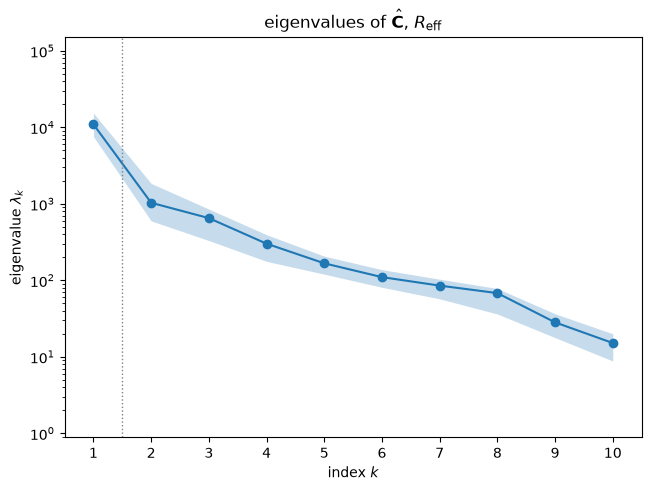

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub, k_max=10)
ax.set_title(r'eigenvalues of $\hat{\mathbf{C}}$, ' + qlabel)
plt.close(fig)
fig

$\lambda_1 = 1.097\times10^4$ and $\lambda_2 = 1036$, so $\lambda_1/\lambda_2 = 10.59$ (bootstrap interval 6.58–17.74), while the next ratios are small: $\lambda_2/\lambda_3 = 1.59$ (1.16–2.93), then 2.16 and 1.81. The eigenvalue gap therefore points to $n = 1$ and to no second gap of comparable size. One direction does not carry everything: the eigenvalues after the first hold 0.185 of the eigenvalue sum. The ratio itself depends on a few samples (checked after the eigenvectors below).

bootstrap mean subspace distance, k = 1..5: 0.071, 0.360, 0.242, 0.259, 0.329


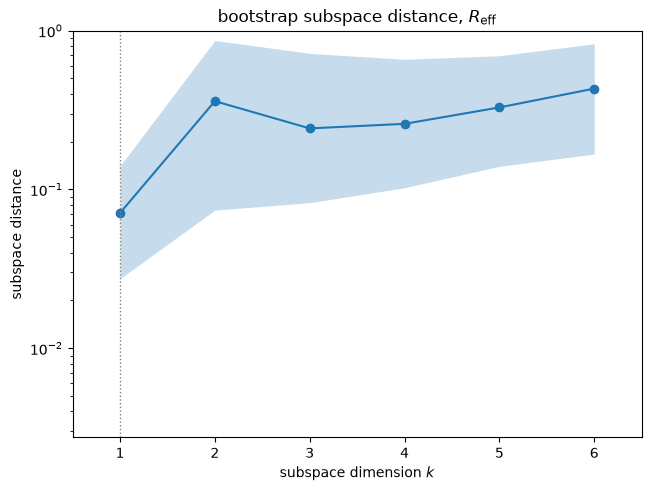

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=6)
ax.set_title('bootstrap subspace distance, ' + qlabel)
plt.close(fig)
dist = sub.bootstrap_distances.mean(axis=0)
print('bootstrap mean subspace distance, k = 1..5: ' + ', '.join(f'{d:.3f}' for d in dist[:5]))
fig

The one-dimensional subspace is well determined (mean bootstrap distance 0.071), while the two-dimensional one is not (0.360): $\lambda_2$ and $\lambda_3$ are too close for $\mathbf w_2$ to be resolved by 1000 samples. With the gap, this settles $n = 1$.

w1 (normalized inputs), by magnitude: gamma -0.472, psi_h -0.425, beta_min +0.328, b -0.317, beta_max +0.290, b1 +0.275, b2 +0.260, rho +0.224, mu_h +0.191, mu_v2 -0.154, mu_h2 +0.135, r_r -0.123, e -0.088, psi_v +0.071, mu_v -0.054, beta -0.026, delta_h -0.016, mu_v3 -0.005, r_s -0.002, T_s -0.001
w2 largest entries: psi_h +0.714, gamma -0.448, mu_h -0.322, beta_min +0.255, beta_max -0.226, b -0.201


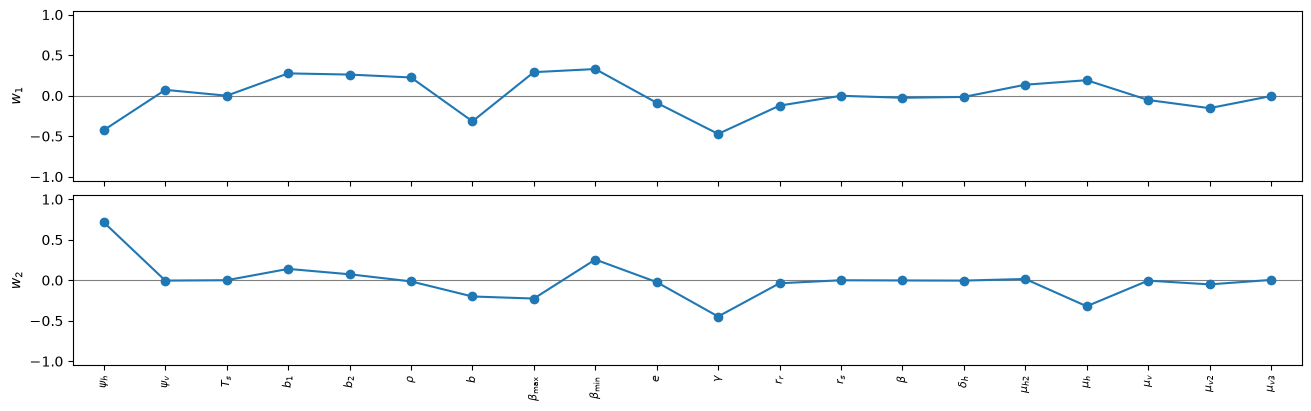

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels)
for a in axes:
    a.tick_params(axis='x', labelsize=8)
fig.set_size_inches(13, 4)
plt.close(fig)
W = sub.W
o = np.argsort(-np.abs(W[:, 0]))
print('w1 (normalized inputs), by magnitude: ' + ', '.join(f'{mm.NAMES[j]} {W[j, 0]:+.3f}' for j in o))
print('w2 largest entries: ' + ', '.join(f'{mm.NAMES[j]} {W[j, 1]:+.3f}' for j in np.argsort(-np.abs(W[:, 1]))[:6]))
fig

$R_{\mathrm{eff}}$ increases along $\mathbf w_1$. Its largest entries are ITN efficacy $\gamma$ ($-0.472$) and human recruitment $\psi_h$ ($-0.425$), then the minimum biting rate $\beta_{\min}$ ($+0.328$), ITN usage $b$ ($-0.317$), the maximum biting rate $\beta_{\max}$ ($+0.290$), the two transmission probabilities $b_1$, $b_2$ ($+0.275$, $+0.260$) and the mosquito-to-human ratio $\rho_1$ ($+0.224$). The treatment parameters hardly enter: $T_s$ ($-0.001$) and $r_s$ ($-0.002$) are negligible, and $e$ is $-0.088$. These signs follow the formula: nets and their efficacy lower $a$ (and $k_v$), and $\psi_h$ lowers $R_{\mathrm{eff}}$ through $1/k_h = \mu_{h2}/(\psi_h - \mu_h)$. The second eigenvector is dominated by $\psi_h$ ($+0.714$), $\gamma$ ($-0.448$) and $\mu_h$ ($-0.322$), the inputs of the two strongly nonlinear factors $a$ and $1/k_h$, but it is not well resolved (above).

**How many samples carry the estimate.** $\hat{\mathbf C}$ is an average of gradient outer products, and $R_{\mathrm{eff}}$ is heavy-tailed, so we check how much of its trace a few samples hold and what happens without them.

In [9]:
GN = G * (mm.UPPER - mm.LOWER) / 2            # gradients with respect to the normalized inputs
print(f'check: lambda_1 from GN = {np.linalg.eigvalsh(GN.T @ GN / len(GN))[-1]:.4f} (library {lam[0]:.4f})')
s_row = np.sum(GN ** 2, axis=1)
o_row = np.argsort(-s_row)
for k in (10, 50):
    keep = np.sort(o_row[k:])
    lk, Wk = np.linalg.eigh(GN[keep].T @ GN[keep] / len(keep))
    lk, Wk = lk[::-1], Wk[:, ::-1]
    print(f'the {k} rows ({100 * k / len(f):.0f} %) with the largest |grad|^2 hold {s_row[o_row[:k]].sum() / s_row.sum():.3f} '
          f'of trace(C); without them lambda1/lambda2 = {lk[0] / lk[1]:.2f}, |w1 . w1(all rows)| = {abs(Wk[:, 0] @ W[:, 0]):.3f}')
f_rank = np.argsort(np.argsort(-f))
g_top = X[o_row[:10], mm.NAMES.index('gamma')]
print(f'R_eff ranks (0 = largest) of those 10 rows: {sorted(int(r) for r in f_rank[o_row[:10]])}; '
      f'{int(np.sum(g_top < 0.4))} of them have gamma < 0.4')
c_ = f - f.mean()
print(f'R_eff: skewness {np.mean(c_ ** 3) / np.mean(c_ ** 2) ** 1.5:.1f}, kurtosis {np.mean(c_ ** 4) / np.mean(c_ ** 2) ** 2:.1f}; '
      f'the 10 largest values hold {np.sort(f ** 2)[::-1][:10].sum() / np.sum(f ** 2):.3f} of sum(R_eff^2)')

check: lambda_1 from GN = 10965.9819 (library 10965.9819)
the 10 rows (1 %) with the largest |grad|^2 hold 0.468 of trace(C); without them lambda1/lambda2 = 16.13, |w1 . w1(all rows)| = 0.992
the 50 rows (5 %) with the largest |grad|^2 hold 0.788 of trace(C); without them lambda1/lambda2 = 13.41, |w1 . w1(all rows)| = 0.977
R_eff ranks (0 = largest) of those 10 rows: [0, 1, 2, 3, 4, 6, 10, 11, 13, 19]; 9 of them have gamma < 0.4
R_eff: skewness 6.7, kurtosis 71.6; the 10 largest values hold 0.519 of sum(R_eff^2)


The direction is robust, the ratio is not. The 10 rows (1 %) with the largest squared gradient norm hold 0.468 of the trace of $\hat{\mathbf C}$, and the 50 largest (5 %) hold 0.788. Without those 10 rows $\lambda_1/\lambda_2$ is 16.13, without the 50 it is 13.41, while $\mathbf w_1$ hardly moves ($|\mathbf w_1\cdot\mathbf w_1'| = 0.992$ and 0.977). The 10 rows are among the 20 largest values of $R_{\mathrm{eff}}$, 9 of them with weak nets ($\gamma < 0.4$); $R_{\mathrm{eff}}$ has skewness 6.7 and kurtosis 71.6, and its 10 largest values hold 0.519 of $\sum R_{\mathrm{eff}}^2$. So $\lambda_1/\lambda_2 = 10.59$ rests on a few samples and should be read as "about 10, with a wide sampling spread" (the bootstrap interval 6.58–17.74 partly reflects this): another 1000-point design could give a noticeably different ratio, but the same leading direction. The choice $n = 1$ does not depend on these rows; removing them widens the gap.

y1 in [-1.66, 1.70]; corr(y1, R_eff) = 0.606, rank corr = 0.854, corr(y1, ln R_eff) = 0.782


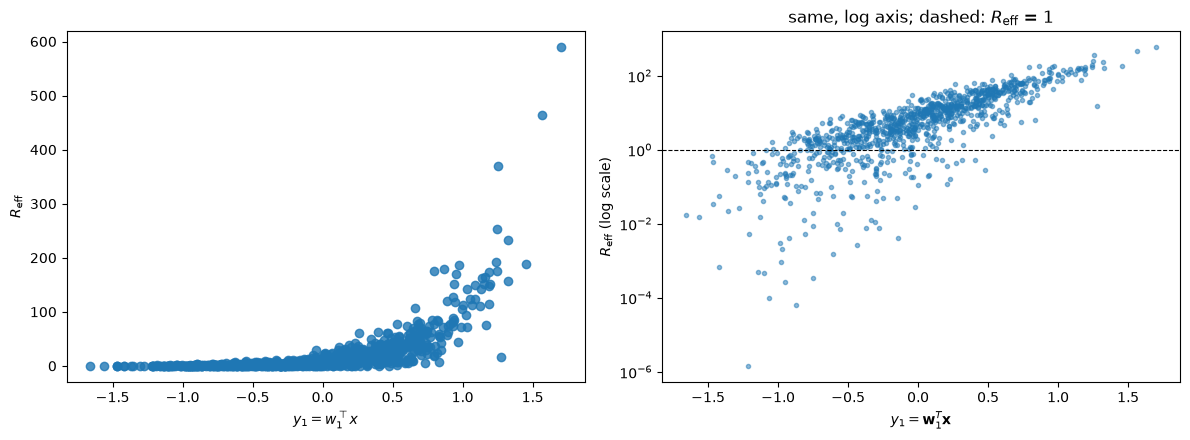

In [10]:
XN = space.to_normalized(X)
y = XN @ W[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=qlabel, ax=axes[0])
axes[1].semilogy(y[:, 0], f, 'o', ms=3, alpha=0.5)
axes[1].axhline(1, color='k', lw=0.8, ls='--')
axes[1].set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{x}$')
axes[1].set_ylabel(qlabel + ' (log scale)')
axes[1].set_title('same, log axis; dashed: ' + qlabel + ' = 1')
fig.tight_layout()
plt.close(fig)
rk = lambda v: np.argsort(np.argsort(v))
print(f'y1 in [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; corr(y1, R_eff) = {np.corrcoef(y[:, 0], f)[0, 1]:.3f}, '
      f'rank corr = {np.corrcoef(rk(y[:, 0]), rk(f))[0, 1]:.3f}, corr(y1, ln R_eff) = {np.corrcoef(y[:, 0], np.log(f))[0, 1]:.3f}')
fig

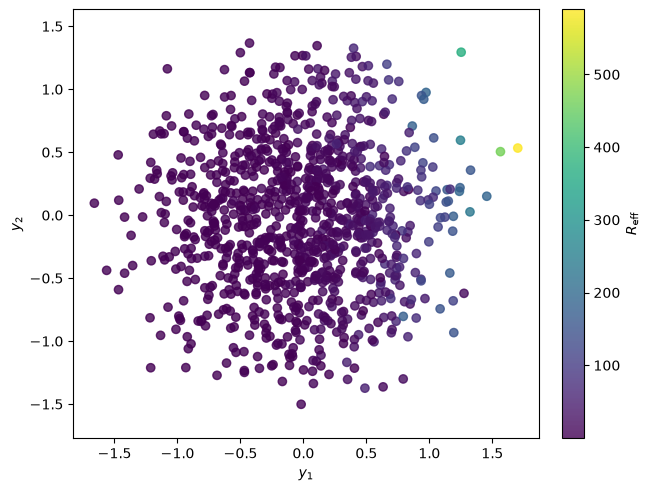

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=f, dims=2, qoi_label=qlabel)
plt.close(fig)
fig

The one-dimensional summary plot shows a convex, fanning trend: $R_{\mathrm{eff}}$ is near zero for $y_1 < 0$ and rises steeply with growing spread for $y_1 > 0$. The linear correlation of $y_1$ with $R_{\mathrm{eff}}$ is only 0.606, but the rank correlation is 0.854; on the log axis (right) the trend is monotone, with a long low tail from the samples with small $\beta_{\min}$. In the two-dimensional plot the largest values sit at large $y_1$, most of them at positive $y_2$.

#### Surrogates on the active variables

Polynomials of degree 2–4 and a radial-basis surrogate in one and two active variables, with leave-one-out $R^2$:

n = 1: LOO R^2 degree 2 0.6509, degree 3 0.7771, degree 4 0.8142, RBF 0.8239


n = 2: LOO R^2 degree 2 0.6877, degree 3 0.8372, degree 4 0.8797, RBF 0.8809


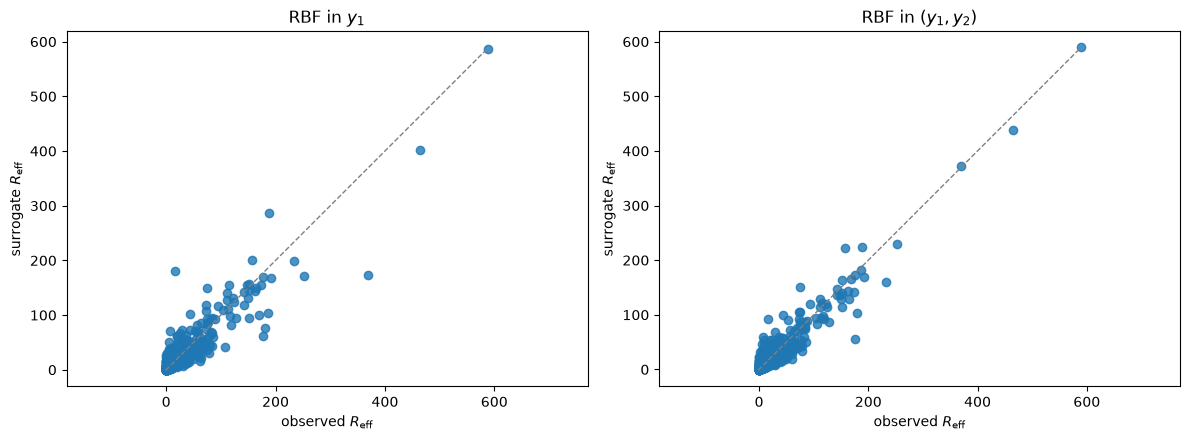

In [12]:
surs = {}
for k in (1, 2):
    sk = ac.with_dimension(sub, k)
    for deg in (2, 3, 4):
        surs[k, deg] = ac.fit_surrogate(X=X, f=f, subspace=sk, kind='poly', degree=deg)
    surs[k, 'rbf'] = ac.fit_surrogate(X=X, f=f, subspace=sk, kind='rbf')
    print(f'n = {k}: LOO R^2 ' + ', '.join(f'{"degree " + str(d) if d != "rbf" else "RBF"} {surs[k, d].loo_r_squared:.4f}'
                                      for d in (2, 3, 4, 'rbf')))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_surrogate_fit(surs[1, 'rbf'], X=X, f=f, qoi_label=qlabel, ax=axes[0])
axes[0].set_title('RBF in $y_1$')
ac.plotting.plot_surrogate_fit(surs[2, 'rbf'], X=X, f=f, qoi_label=qlabel, ax=axes[1])
axes[1].set_title('RBF in $(y_1, y_2)$')
fig.tight_layout()
plt.close(fig)
fig

In one active variable the leave-one-out $R^2$ is 0.651 (quadratic), 0.777 (cubic), 0.814 (quartic) and 0.824 (RBF); a second variable raises the best to 0.881. One active variable thus captures the main trend but not the spread at large $y_1$, consistent with the 0.185 of the eigenvalue sum outside $\mathbf w_1$. The second variable helps a little; it is not well resolved, so we keep $n = 1$ and report the surrogate's limits rather than a larger $n$.

**The spectral radius $\sqrt{R_{\mathrm{eff}}}$.** The usual next-generation reproduction number is $\rho(FV^{-1}) = \sqrt{R_{\mathrm{eff}}}$, which is less skewed. Its gradient is $\nabla R_{\mathrm{eff}}/(2\sqrt{R_{\mathrm{eff}}})$, so the same files give its active subspace:

In [13]:
fs = np.sqrt(f)
sub_s = ac.active_subspace(space=space, X=X, f=fs, grads=G / (2 * fs[:, None]), estimator='as', nboot=500, rng=SEED)
sub_s = ac.orient(sub_s, by='covariance', X=X, f=fs, columns=1)
ls_ = sub_s.eigenvalues
print(f'sqrt(R_eff): ratios lambda_k/lambda_k+1, k = 1..3: {np.array2string(ls_[:3] / ls_[1:4], precision=3)}; '
      f'share left out with n = 1: {ls_[1:].sum() / ls_.sum():.3f}')
print(f'|w1(sqrt R_eff) . w1(R_eff)| = {abs(sub_s.W[:, 0] @ W[:, 0]):.3f}; bootstrap mean distance n = 1: '
      f'{sub_s.bootstrap_distances.mean(axis=0)[0]:.3f}')
for d in (2, 'rbf'):
    s_ = ac.fit_surrogate(X=X, f=fs, subspace=ac.with_dimension(sub_s, 1), kind='poly' if d == 2 else 'rbf', degree=2)
    print(f'sqrt(R_eff), n = 1, {"quadratic" if d == 2 else "RBF"}: LOO R^2 {s_.loo_r_squared:.4f}')

sqrt(R_eff): ratios lambda_k/lambda_k+1, k = 1..3: [6.992 2.209 1.044]; share left out with n = 1: 0.263
|w1(sqrt R_eff) . w1(R_eff)| = 0.980; bootstrap mean distance n = 1: 0.039
sqrt(R_eff), n = 1, quadratic: LOO R^2 0.8725


sqrt(R_eff), n = 1, RBF: LOO R^2 0.8844


For $\sqrt{R_{\mathrm{eff}}}$ the first gap is smaller, $\lambda_1/\lambda_2 = 6.99$, but its direction is close to that of $R_{\mathrm{eff}}$ ($|\mathbf w_1\cdot\mathbf w_1'| = 0.980$) and a quadratic in its single active variable has leave-one-out $R^2 = 0.873$. The heavy tail of $R_{\mathrm{eff}}$, not the direction, is what limits the one-variable surrogate above.

**The sample estimate for $\ln R_{\mathrm{eff}}$.** For $\ln R_{\mathrm{eff}}$, $\mathbf C$ is not finite under Table 3's density (above), but the sample average can still be formed from the same files (gradient $\nabla R_{\mathrm{eff}}/R_{\mathrm{eff}}$):

In [14]:
fl = np.log(f)
sub_l = ac.active_subspace(space=space, X=X, f=fl, grads=G / f[:, None], estimator='as', nboot=500, rng=SEED)
ll = sub_l.eigenvalues
bl = sub_l.bootstrap_eigenvalues[:, 0] / sub_l.bootstrap_eigenvalues[:, 1]
GL = G / f[:, None] * (mm.UPPER - mm.LOWER) / 2
sl_row = np.sum(GL ** 2, axis=1)
jb = mm.NAMES.index('beta_min')
print(f'ln R_eff: lambda1/lambda2 = {ll[0] / ll[1]:.0f} (95 % bootstrap interval [{np.percentile(bl, 2.5):.0f}, {np.percentile(bl, 97.5):.0f}])')
print(f'beta_min holds {np.sum(GL[:, jb] ** 2) / sl_row.sum():.4f} of the trace; 1 - |w1[beta_min]| = {1 - abs(sub_l.W[jb, 0]):.1e}; '
      f'the 10 rows with the largest |grad|^2 hold {np.sort(sl_row)[::-1][:10].sum() / sl_row.sum():.3f} of the trace')

ln R_eff: lambda1/lambda2 = 1205 (95 % bootstrap interval [53, 3436])
beta_min holds 0.9988 of the trace; 1 - |w1[beta_min]| = 4.2e-06; the 10 rows with the largest |grad|^2 hold 0.987 of the trace


The sample estimate is a trivial one-dimensional subspace along the $\beta_{\min}$ axis: $\lambda_1/\lambda_2 = 1205$ (bootstrap interval 53–3436), $\beta_{\min}$ holds 0.9988 of the trace, and $1 - |w_{\beta_{\min},1}|$ is of order $10^{-6}$. It is driven by the samples with the smallest $\beta_{\min}$ (the 10 rows with the largest squared gradient hold 0.987 of the trace). Because $\mathbf C$ is not finite under Table 3's density, this sample average has no limit as $M$ grows, which the wide bootstrap interval reflects. It says only that $\ln R_{\mathrm{eff}}$ is most sensitive to $\beta_{\min}$ near 0, as $R_{\mathrm{eff}} \propto a^2$ with $a \to 0$ as $\beta_{\min} \to 0$ already shows; we therefore keep $R_{\mathrm{eff}}$ (and $\sqrt{R_{\mathrm{eff}}}$) as the quantities of interest.

### Comparison with the paper

The paper [[1]][R1] does not compute an active subspace. It ranks the parameters by PRCC [[4]][R4] on a 1000-point Latin hypercube (SaSAT [[3]][R3]; Sec. 5.2.1, pp. 18–21) and shows the values as tornado plots for $R_r$, $R_s$ and $R_{\mathrm{eff}}$ (Figs. 3 and 4, p. 20; Fig. 5, p. 21; no numbers printed), and it reports that 210 of its 1000 samples gave $R_{\mathrm{eff}} < 1$ (Sec. 5.2.2, p. 21). It reports no variance-based (Sobol') indices. We compute PRCC on the shipped design and, to show the sampling spread, on 50 further 1000-point Latin hypercubes drawn with seeds derived from `SEED`. The paper's PRCC values below were read from Fig. 5 by measuring the bar ends on a 300 dpi rendering of p. 21 (reading precision about 0.005; the bar of $\mu_{v3}$ is too short to see, so its value is below about 0.005 in magnitude). We also give the activity scores $\alpha_i = \lambda_1 w_{i1}^2$ [[5]][R5] (scaled to a maximum of 1), a derivative-based ranking.

In [15]:
PAPER_FIG5 = {'beta_min': 0.863, 'gamma': -0.657, 'b2': 0.631, 'b1': 0.624, 'psi_h': -0.509, 'rho': 0.489,
              'b': -0.468, 'beta_max': 0.466, 'mu_h2': 0.291, 'mu_h': 0.255, 'e': -0.236, 'mu_v2': -0.234,
              'psi_v': 0.221, 'r_r': -0.216, 'mu_v': -0.128, 'T_s': -0.062, 'beta': -0.047, 'r_s': -0.021,
              'delta_h': -0.015, 'mu_v3': 0.0}       # read from Fig. 5, p. 21 (bar ends at 300 dpi)
P = mm.prcc(X, f)
def kv_over_kh(Xd):
    c = {n: Xd[:, i] for i, n in enumerate(mm.NAMES)}
    return ((c['psi_v'] - c['mu_v'] - c['mu_v3'] * c['b'] * c['gamma']) / c['mu_v2']) / ((c['psi_h'] - c['mu_h']) / c['mu_h2'])


IN_RR = [j for j, n in enumerate(mm.NAMES) if n not in ('e', 'T_s', 'r_s')]    # the 17 inputs of R_r
reps, nbelow, nbelow_alt, reps_r, reps_s = [], [], [], [], []
for r in range(1, 51):
    Xr = mm.sample(1000, np.random.default_rng([SEED, r]))
    fr_ = mm.reffs(Xr)
    reps.append(mm.prcc(Xr, fr_))
    nbelow.append(int(np.sum(fr_ < 1)))
    nbelow_alt.append(int(np.sum(fr_ / kv_over_kh(Xr) < 1)))
    pr_ = np.array([mm.strain_parts(x) for x in Xr])
    reps_r.append(mm.prcc(Xr[:, IN_RR], pr_[:, 0]))
    reps_s.append(mm.prcc(Xr, pr_[:, 1]))
reps = np.array(reps)
lo_, hi_ = np.percentile(reps, 2.5, axis=0), np.percentile(reps, 97.5, axis=0)
alpha_s = ac.activity_scores(sub, n=1)
alpha_s = alpha_s / alpha_s.max()
pv = np.array([PAPER_FIG5[n] for n in mm.NAMES])
print(f"{'input':9s} {'Fig. 5':>7s} {'PRCC':>7s} {'50 designs (2.5-97.5 %)':>24s} {'activity':>9s}")
for j in np.argsort(-np.abs(pv)):
    print(f'{mm.NAMES[j]:9s} {pv[j]:7.3f} {P[j]:7.3f}   [{lo_[j]:6.3f}, {hi_[j]:6.3f}]      {alpha_s[j]:9.3f}')
top_paper = [mm.NAMES[j] for j in np.argsort(-np.abs(pv))[:5]]
top_ours = [mm.NAMES[j] for j in np.argsort(-np.abs(P))[:5]]
top_act = [mm.NAMES[j] for j in np.argsort(-alpha_s)[:5]]
inside = (pv >= lo_ - 0.005) & (pv <= hi_ + 0.005)
print(f'\ntop five, paper Fig. 5: {top_paper}\ntop five, PRCC here:    {top_ours}\ntop five, activity:     {top_act}')
print(f'Fig. 5 value inside the 50-design range (+-0.005 reading error) for {int(inside.sum())} of 20 inputs; '
      f'outside: {[mm.NAMES[j] for j in np.nonzero(~inside)[0]]}')
print(f'max |PRCC here - Fig. 5| = {np.max(np.abs(P - pv)):.3f} ({mm.NAMES[int(np.argmax(np.abs(P - pv)))]}); '
      f'rank correlation of |PRCC| with activity scores = {np.corrcoef(rk(np.abs(P)), rk(alpha_s))[0, 1]:.3f}')
nb = int(np.sum(f < 1))
p_hat = nb / len(f)
hw = 1.96 * np.sqrt(p_hat * (1 - p_hat) / len(f))
f_alt = f / kv_over_kh(X)                      # the reading xi1 = a b1 rho (15 inputs)
P_alt = mm.prcc(X, f_alt)
print(f'reading xi1 = a b1 rho: top five {[mm.NAMES[j] for j in np.argsort(-np.abs(P_alt))[:5]]}, '
      f'PRCC psi_h {P_alt[mm.NAMES.index("psi_h")]:+.3f}, max |PRCC - Fig. 5| {np.max(np.abs(P_alt - pv)):.3f}, '
      f'R_eff < 1 at {int(np.sum(f_alt < 1))} of 1000 (50 further designs {min(nbelow_alt)}-{max(nbelow_alt)})')
print(f'R_eff < 1: {nb} of {len(f)} here (95 % interval {1000 * (p_hat - hw):.0f}-{1000 * (p_hat + hw):.0f}); '
      f'50 further designs: {min(nbelow)}-{max(nbelow)} (median {int(np.median(nbelow))}); paper: 210')

input      Fig. 5    PRCC  50 designs (2.5-97.5 %)  activity
beta_min    0.863   0.850   [ 0.842,  0.868]          0.483
gamma      -0.657  -0.621   [-0.644, -0.583]          1.000
b2          0.631   0.621   [ 0.563,  0.646]          0.303
b1          0.624   0.580   [ 0.545,  0.618]          0.338
psi_h      -0.509  -0.543   [-0.518, -0.424]          0.809
rho         0.489   0.465   [ 0.403,  0.493]          0.225
b          -0.468  -0.446   [-0.485, -0.404]          0.451
beta_max    0.466   0.437   [ 0.391,  0.476]          0.377
mu_h2       0.291   0.186   [ 0.198,  0.304]          0.081
mu_h        0.255   0.281   [ 0.197,  0.305]          0.163
e          -0.236  -0.205   [-0.268, -0.134]          0.035
mu_v2      -0.234  -0.260   [-0.313, -0.186]          0.107
psi_v       0.221   0.241   [ 0.127,  0.256]          0.023
r_r        -0.216  -0.158   [-0.215, -0.108]          0.068
mu_v       -0.128  -0.123   [-0.181, -0.087]          0.013
T_s        -0.062  -0.019   [-0.063,  0

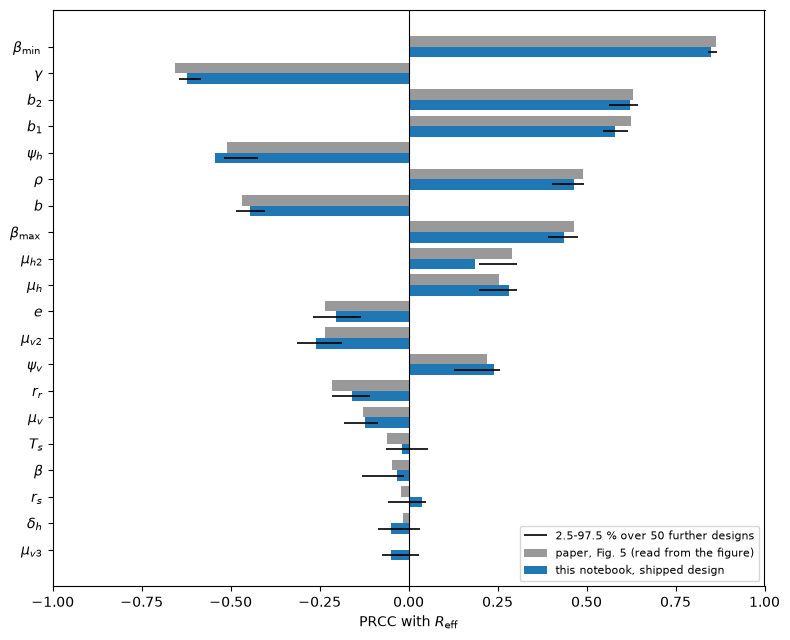

In [16]:
fig, ax = plt.subplots(figsize=(8, 6.5))
order_ = np.argsort(np.abs(pv))
yy = np.arange(len(order_))
ax.barh(yy + 0.2, pv[order_], height=0.4, color='0.6', label='paper, Fig. 5 (read from the figure)')
ax.barh(yy - 0.2, P[order_], height=0.4, color='C0', label='this notebook, shipped design')
ax.hlines(yy - 0.2, lo_[order_], hi_[order_], color='k', lw=1.2, label='2.5-97.5 % over 50 further designs')
ax.set_yticks(yy)
ax.set_yticklabels([labels[j] for j in order_])
ax.axvline(0, color='k', lw=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel('PRCC with ' + qlabel)
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

**The strain reproduction numbers (Figs. 3 and 4, p. 20).** `outputs.csv` also holds $R_r$ and $R_s$, so the two other tornado plots can be compared. Fig. 3 ($R_r$) has 17 bars: the 20 inputs without $e$, $T_s$ and $r_s$, which do not enter $R_r = \xi_1 k_1(1-\beta)/(p_2\psi_v)$; the five density-dependent parameters $\mu_h, \mu_{h2}, \mu_v, \mu_{v2}, \mu_{v3}$ are among the 17, so the paper's $R_r$ also contains $k_v/k_h$ (with $\xi_1 = ab_1\rho_1$ it would have 12 bars). We compute PRCC for $R_r$ over its 17 inputs and for $R_s$ over all 20, on the shipped design and on the same 50 further designs. The paper's values were read from the bar ends on a 300 dpi rendering of p. 20 in the same way as for Fig. 5 (reading precision about 0.005); the leading five in each figure are also listed in the text (p. 19).

In [17]:
PAPER_FIG3 = {'beta_min': 0.839, 'gamma': -0.573, 'b1': 0.573, 'b2': 0.557, 'beta': -0.531, 'psi_h': -0.451,
              'rho': 0.447, 'beta_max': 0.431, 'b': -0.386, 'mu_v2': -0.251, 'mu_h2': 0.244, 'r_r': -0.196,
              'mu_h': 0.191, 'psi_v': 0.173, 'mu_v': -0.109, 'delta_h': -0.024, 'mu_v3': -0.013}   # Fig. 3, p. 20
PAPER_FIG4 = {'beta_min': 0.852, 'gamma': -0.625, 'b1': 0.600, 'b2': 0.598, 'b': -0.502, 'rho': 0.471,
              'beta_max': 0.454, 'psi_h': -0.441, 'e': -0.371, 'mu_v2': -0.295, 'beta': 0.248, 'mu_h2': 0.245,
              'mu_h': 0.212, 'psi_v': 0.195, 'mu_v': -0.148, 'r_r': -0.127, 'delta_h': -0.038, 'T_s': 0.032,
              'r_s': -0.020, 'mu_v3': -0.012}                                                           # Fig. 4, p. 20
TOP5_TEXT = {'R_r': ['beta_min', 'gamma', 'b1', 'b2', 'beta'], 'R_s': ['beta_min', 'gamma', 'b1', 'b2', 'b']}  # p. 19
dep = []
for j in range(mm.M_IN):
    xp = x0.copy()
    xp[j] *= 1.1
    dep.append(mm.strain_parts(xp)[0] != Rr0)
print(f'R_r changes with {sum(dep)} of the 20 inputs; not with {[mm.NAMES[j] for j in range(mm.M_IN) if not dep[j]]}; '
      f'Fig. 3 has {len(PAPER_FIG3)} bars')
for qn, cols, Pq, R_ in (('R_r', IN_RR, mm.prcc(X[:, IN_RR], F[:, 1]), np.array(reps_r)),
                         ('R_s', list(range(mm.M_IN)), mm.prcc(X, F[:, 2]), np.array(reps_s))):
    names_q = [mm.NAMES[j] for j in cols]
    fig_q = PAPER_FIG3 if qn == 'R_r' else PAPER_FIG4
    pq = np.array([fig_q[n] for n in names_q])
    lo_q, hi_q = np.percentile(R_, 2.5, axis=0), np.percentile(R_, 97.5, axis=0)
    print(f"\n{qn}: {'input':9s} {'Fig.':>7s} {'PRCC':>7s} {'50 designs (2.5-97.5 %)':>24s}")
    for k in [names_q.index(n) for n in fig_q]:                  # in the figure's bar order
        print(f'     {names_q[k]:9s} {pq[k]:7.3f} {Pq[k]:7.3f}   [{lo_q[k]:6.3f}, {hi_q[k]:6.3f}]')
    ins = (pq >= lo_q - 0.005) & (pq <= hi_q + 0.005)
    big = np.abs(pq) >= 0.1
    print(f'{qn}: top five, paper (p. 19 and bar order): {TOP5_TEXT[qn]}; PRCC here: {[names_q[k] for k in np.argsort(-np.abs(Pq))[:5]]}')
    print(f'{qn}: shipped-design value outside its own 50-design range for {[names_q[k] for k in np.nonzero((Pq < lo_q) | (Pq > hi_q))[0]]}')
    print(f'{qn}: figure value inside the 50-design range (+-0.005) for {int(ins.sum())} of {len(pq)}; outside: '
          f'{[names_q[k] for k in np.nonzero(~ins)[0]]}; same sign for {int(np.sum(np.sign(pq[big]) == np.sign(Pq[big])))} '
          f'of the {int(big.sum())} with |figure value| >= 0.1; max |PRCC here - figure| = {np.max(np.abs(Pq - pq)):.3f} '
          f'({names_q[int(np.argmax(np.abs(Pq - pq)))]})')

R_r changes with 17 of the 20 inputs; not with ['T_s', 'e', 'r_s']; Fig. 3 has 17 bars

R_r: input        Fig.    PRCC  50 designs (2.5-97.5 %)
     beta_min    0.839   0.840   [ 0.837,  0.858]
     gamma      -0.573  -0.599   [-0.636, -0.567]
     b1          0.573   0.566   [ 0.527,  0.603]
     b2          0.557   0.604   [ 0.542,  0.629]
     beta       -0.531  -0.509   [-0.559, -0.466]
     psi_h      -0.451  -0.522   [-0.508, -0.398]
     rho         0.447   0.444   [ 0.394,  0.487]
     beta_max    0.431   0.402   [ 0.365,  0.461]
     b          -0.386  -0.423   [-0.472, -0.385]
     mu_v2      -0.251  -0.256   [-0.302, -0.193]
     mu_h2       0.244   0.156   [ 0.180,  0.302]
     r_r        -0.196  -0.153   [-0.213, -0.107]
     mu_h        0.191   0.248   [ 0.198,  0.289]
     psi_v       0.173   0.225   [ 0.132,  0.250]
     mu_v       -0.109  -0.123   [-0.179, -0.082]
     delta_h    -0.024  -0.044   [-0.083,  0.040]
     mu_v3      -0.013  -0.044   [-0.093,  0.028]
R_r: t

The count of bars agrees with the formula: $R_r$ changes with 17 of the 20 inputs, not with $e$, $T_s$, $r_s$, and Fig. 3 has 17 bars, the five density-dependent parameters among them. The values agree in sign for every bar with magnitude at least 0.1 (15 for $R_r$, 16 for $R_s$), and the figure values lie inside the 2.5–97.5 % range over 50 further designs for 16 of the 17 inputs of $R_r$ (outside: $\mu_h$, 0.191 against [0.198, 0.289]) and for 19 of the 20 of $R_s$ (outside: $b$, $-0.502$ against [$-0.484$, $-0.403$]). For example, for $R_s$ the value of $e$ is $-0.371$ in Fig. 4 and $-0.336$ here, $\beta$ is $+0.248$ and $+0.304$ (positive in both), $\psi_h$ is $-0.441$ and $-0.545$, and $b$ is $-0.502$ and $-0.450$; for $R_r$, $\beta$ is $-0.531$ and $-0.509$. The orders within the leading group differ: for $R_r$ the paper's top five (p. 19) are $\beta_{\min}$, $\gamma$, $b_1$, $b_2$, $\beta$, and here $\beta_{\min}$, $b_2$, $\gamma$, $b_1$, $\psi_h$ (with $\beta$ sixth); for $R_s$ the paper has $\beta_{\min}$, $\gamma$, $b_1$, $b_2$, $b$, and here $\beta_{\min}$, $\gamma$, $b_2$, $b_1$, $\psi_h$, while $\psi_h$ is eighth in Fig. 4. The largest differences on the shipped design (0.088 for $\mu_{h2}$ in $R_r$, 0.104 for $\psi_h$ in $R_s$) are where this design's own value lies outside the range of the other 50 designs. Figs. 3 and 4 thus agree with this data set about as well as Fig. 5 does: the same parameters, the same signs and similar magnitudes, but not the same order within the leading group.

| Quantity | Paper value | Notebook value |
|---|---|---|
| inputs of $R_{\mathrm{eff}}$ | 20 (text, p. 18–19; Fig. 5, p. 21); Table 3 has 23 rows | 20: Table 3 without $\alpha$, $\alpha_s$, $\alpha_r$, which do not enter Eq. (19) |
| top five PRCC parameters | $\beta_{\min}$, $\gamma$, $b_2$, $b_1$, $\psi_h$ (p. 21, Fig. 5) | $\beta_{\min}$, $\gamma$, $b_2$, $b_1$, $\psi_h$ (shipped design) |
| PRCC of $\beta_{\min}$, $\gamma$, $b_2$, $b_1$, $\psi_h$ | 0.863, −0.657, 0.631, 0.624, −0.509 (read from Fig. 5) | 0.850, −0.621, 0.621, 0.580, −0.543 |
| largest PRCC difference from Fig. 5 | – | 0.105 ($\mu_{h2}$: 0.291 in Fig. 5, 0.186 here) |
| inputs of $R_r$ | 17 bars in Fig. 3 (p. 20) | 17: $R_r$ does not depend on $e$, $T_s$, $r_s$ |
| top five PRCC for $R_r$ | $\beta_{\min}$, $\gamma$, $b_1$, $b_2$, $\beta$ (p. 19, Fig. 3) | $\beta_{\min}$, $b_2$, $\gamma$, $b_1$, $\psi_h$ ($\beta$ sixth) |
| top five PRCC for $R_s$ | $\beta_{\min}$, $\gamma$, $b_1$, $b_2$, $b$ (p. 19, Fig. 4) | $\beta_{\min}$, $\gamma$, $b_2$, $b_1$, $\psi_h$ |
| figure values inside the 50-design PRCC range | Figs. 3, 4 (read from the figures) | 16 of 17 for $R_r$, 19 of 20 for $R_s$; all signs of bars of magnitude ≥ 0.1 agree |
| samples with $R_{\mathrm{eff}} < 1$ | 210 of 1000 (p. 21) | 199 of 1000 (95 % interval 174–224); 50 further designs 180–223 (median 207) |
| $R_{\mathrm{eff}}$ at the Table 3 baselines | not reported | 49.21 |
| active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2 = 10.59$ (16.13 without the 10 samples with the largest gradients); $\mathbf w_1$ led by $\gamma$, $\psi_h$, $\beta_{\min}$, $b$ |
| Sobol' indices | not reported | not computed |

The paper's ranking is reproduced: the same five leading parameters in the same order, the Fig. 5 value inside the 2.5–97.5 % range over 50 further designs for 18 of the 20 inputs (the two others, $\gamma$ and $b_1$, lie 0.013 and 0.006 outside it), and a count of samples below one that brackets the paper's 210. The largest difference on the shipped design, 0.105 for $\mu_{h2}$, comes from that design: its own value, 0.186, is below the range of the other 50 designs. This agreement shows that the paper's $R_{\mathrm{eff}}$ contains the factor $k_v/k_h$. With $\xi_1 = ab_1\rho_1$ instead (15 inputs), $\psi_h$ falls out of the top five (PRCC $-0.094$ on the shipped design), the largest difference from Fig. 5 is 0.527, and 353 of the 1000 samples have $R_{\mathrm{eff}} < 1$ (338–382 over the 50 designs). The active subspace and PRCC agree on the leading group ($\beta_{\min}$, $\gamma$, $b$, $b_1$, $b_2$, $\psi_h$, $\rho_1$, $\beta_{\max}$) and that treatment matters little (p. 21), but they order it differently: PRCC measures monotone association of ranks, while the activity scores weight the squared derivative, which is largest where $R_{\mathrm{eff}}$ is large, so $\gamma$ and $\psi_h$, the inputs of the fast-growing factors, lead the activity scores while $\beta_{\min}$ leads PRCC. Over all 20 inputs the rank correlation of $|\mathrm{PRCC}|$ with the activity scores is 0.935.

### References

[1] S. Bala and B. Gimba. [Global sensitivity analysis to study the impacts of bed-nets, drug treatment, and their efficacies on a two-strain malaria model](https://doi.org/10.3390/mca24010032). *Mathematical and Computational Applications*, 24(1):32, 2019.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] A. Hoare, D. G. Regan, and D. P. Wilson. [Sampling and sensitivity analyses tools (SaSAT) for computational modelling](https://doi.org/10.1186/1742-4682-5-4). *Theoretical Biology and Medical Modelling*, 5:4, 2008.

[4] S. Marino, I. B. Hogue, C. J. Ray, and D. E. Kirschner. [A methodology for performing global uncertainty and sensitivity analysis in systems biology](https://doi.org/10.1016/j.jtbi.2008.04.011). *Journal of Theoretical Biology*, 254(1):178–196, 2008.

[5] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[6] P. van den Driessche and J. Watmough. [Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission](https://doi.org/10.1016/S0025-5564(02)00108-6). *Mathematical Biosciences*, 180(1–2):29–48, 2002.

[R1]: https://doi.org/10.3390/mca24010032
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1186/1742-4682-5-4
[R4]: https://doi.org/10.1016/j.jtbi.2008.04.011
[R5]: https://doi.org/10.1016/j.ress.2017.01.013
[R6]: https://doi.org/10.1016/S0025-5564(02)00108-6

In [18]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 11.6 s
